In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from ppghr.data import ACTIVITY_NAMES, FS_ACC, FS_PPG, load_processed
from ppghr.windows import load_all_windows, make_windows


from ppghr.baseline import bandpass, estimate_hr_fft, spectrum_bpm
from ppghr.metrics import mae, within

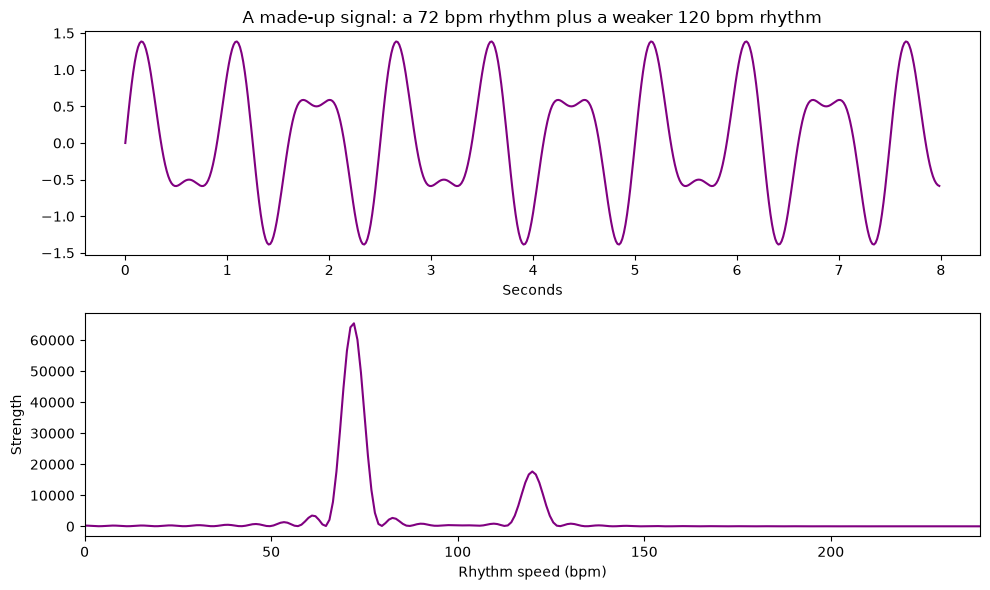

In [5]:
fs = 64
t = np.arange(8 * fs) / fs
fake = np.sin(2 * np.pi * 1.2 * t) + 0.5 * np.sin(2 * np.pi * 2.0 * t)
bpm, power = spectrum_bpm(fake, fs)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6))
ax1.plot(t, fake, color="purple")
ax1.set_xlabel("Seconds")
ax1.set_title("A made-up signal: a 72 bpm rhythm plus a weaker 120 bpm rhythm")
ax2.plot(bpm, power, color="purple")
ax2.set_xlim(0, 240)
ax2.set_xlabel("Rhythm speed (bpm)")
ax2.set_ylabel("Strength")
plt.tight_layout()
plt.show()

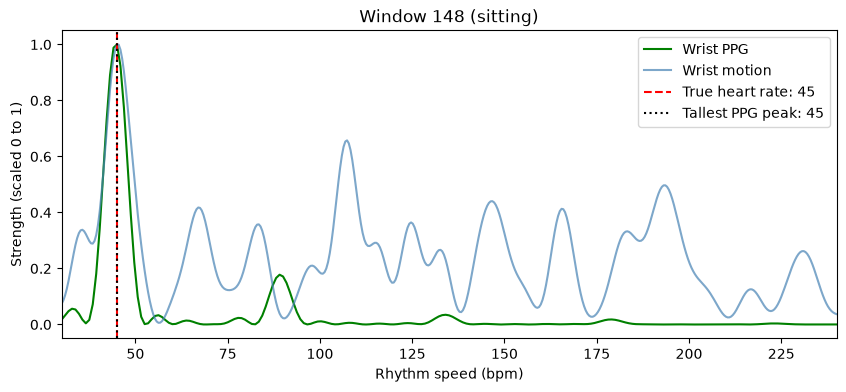

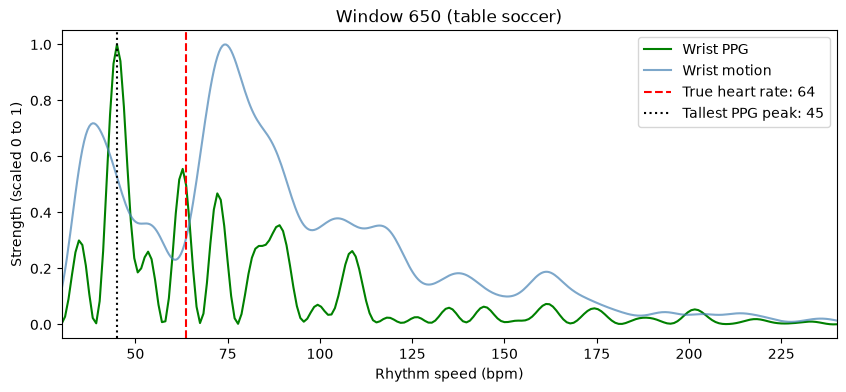

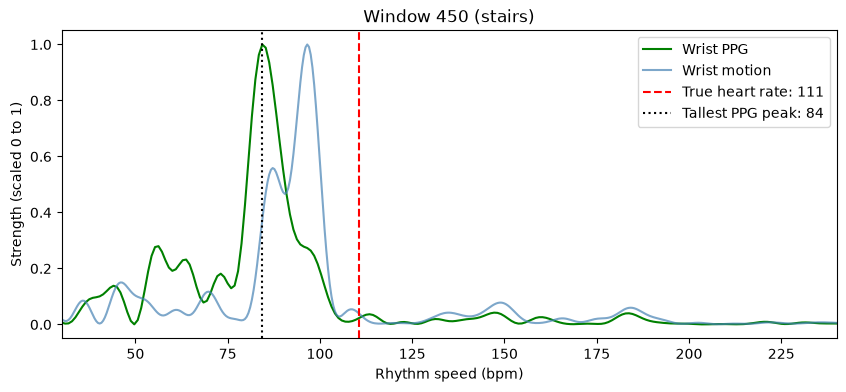

In [6]:
s1 = make_windows(load_processed("S1"))

def plot_spectrum(windows, i):
    ppg = bandpass(windows["ppg"][i], FS_PPG)
    acc = bandpass(windows["acc"][i].T, FS_ACC)
    bpm, ppg_power = spectrum_bpm(ppg, FS_PPG)
    bpm_acc, acc_power = spectrum_bpm(acc, FS_ACC)
    acc_power = acc_power.sum(axis=0)
    true_hr = windows["hr"][i]
    in_range = (bpm >= 30) & (bpm <= 240)
    estimate = bpm[in_range][np.argmax(ppg_power[in_range])]
    activity = ACTIVITY_NAMES[int(windows["activity"][i])]

    plt.figure(figsize=(10, 4))
    plt.plot(bpm, ppg_power / ppg_power.max(), color="green", label="Wrist PPG")
    plt.plot(bpm_acc, acc_power / acc_power.max(), color="steelblue", alpha=0.7, label="Wrist motion")
    plt.axvline(true_hr, color="red", linestyle="--", label=f"True heart rate: {true_hr:.0f}")
    plt.axvline(estimate, color="black", linestyle=":", label=f"Tallest PPG peak: {estimate:.0f}")
    plt.xlim(30, 240)
    plt.xlabel("Rhythm speed (bpm)")
    plt.ylabel("Strength (scaled 0 to 1)")
    plt.title(f"Window {i} ({activity})")
    plt.legend()
    plt.show()

for i in [148, 650, 450]:
    plot_spectrum(s1, i)

In [7]:
data = load_all_windows()
estimate = estimate_hr_fft(data["ppg"])
print(f"MAE over all windows: {mae(estimate, data['hr']):.1f} bpm")
print(f"Within 5 bpm: {within(estimate, data['hr']):.1f}% of windows")

MAE over all windows: 17.8 bpm
Within 5 bpm: 53.6% of windows


In [8]:
results = pd.DataFrame({
    "subject": data["subject"],
    "activity": [ACTIVITY_NAMES[a] for a in data["activity"]],
    "true_hr": data["hr"],
    "estimate": estimate,
})
results["abs_error"] = (results["estimate"] - results["true_hr"]).abs()

per_subject = results.groupby("subject")["abs_error"].mean()
print(f"Average of the 15 subjects' MAEs: {per_subject.mean():.1f} bpm")
results.groupby("activity")["abs_error"].mean().round(1).sort_values()

Average of the 15 subjects' MAEs: 17.9 bpm


activity
sitting          2.7
working          8.0
driving         12.2
lunch           13.2
transition      22.2
walking         27.8
cycling         27.9
table soccer    30.2
stairs          37.8
Name: abs_error, dtype: float64

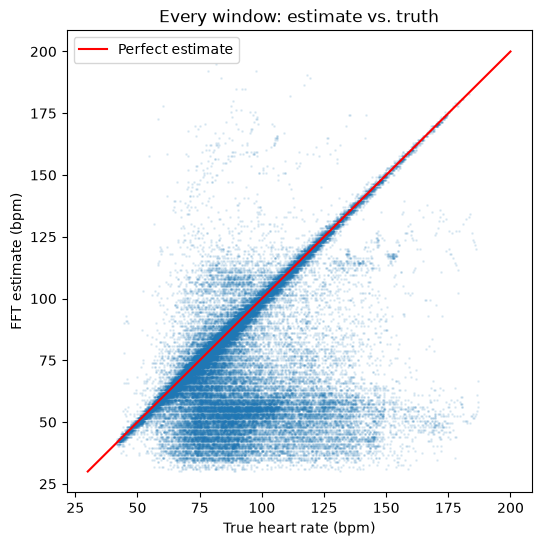

In [9]:
plt.figure(figsize=(6, 6))
plt.scatter(results["true_hr"], results["estimate"], s=1, alpha=0.1)
plt.plot([30, 200], [30, 200], color="red", label="Perfect estimate")
plt.xlabel("True heart rate (bpm)")
plt.ylabel("FFT estimate (bpm)")
plt.title("Every window: estimate vs. truth")
plt.legend()
plt.show()